**EDA** : Exploratory Data Analysis is the process where we explore data statistically so that we get to know what all are the information inside dataset

In this we will explore data of patients in a hospital and create analytical dashboard to show required information on website

* hospital_data.db is the file where database dataset will be stored
* create_hospital_db.sql is the file by using which we will create a database inside hospital_data.db

In [1]:
import sqlite3 as sql

In [2]:
conn=sql.connect('hospital_data.db') # connecting database file for storage

In [3]:
cursor=conn.cursor() # creating cursor to execute sql queries by using python
with open('create_hospital_db.sql','r',encoding='utf-8-sig') as file:
    queries=file.read() # reading sql queries to create database inside hospital_data.db

In [4]:
queries.split('\n')

['CREATE TABLE IF NOT EXISTS payers (',
 '    Id CHAR(36) PRIMARY KEY,',
 '    NAME VARCHAR(100),',
 '    ADDRESS VARCHAR(255),',
 '    CITY VARCHAR(100),',
 '    STATE_HEADQUARTERED CHAR(2),',
 '    ZIP VARCHAR(10),',
 '    PHONE VARCHAR(20)',
 ');',
 '',
 '-- Insert data into payers table',
 'INSERT INTO payers (Id, NAME, ADDRESS, CITY, STATE_HEADQUARTERED, ZIP, PHONE) VALUES',
 "('b3221cfc-24fb-339e-823d-bc4136cbc4ed', 'Dual Eligible', '7500 Security Blvd', 'Baltimore', 'MD', '21244', '1-877-267-2323'),",
 "('7caa7254-5050-3b5e-9eae-bd5ea30e809c', 'Medicare', '7500 Security Blvd', 'Baltimore', 'MD', '21244', '1-800-633-4227'),",
 "('7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a', 'Medicaid', '7500 Security Blvd', 'Baltimore', 'MD', '21244', '1-877-267-2323'),",
 "('d47b3510-2895-3b70-9897-342d681c769d', 'Humana', '500 West Main St', 'Louisville', 'KY', '40018', '1-844-330-7799'),",
 "('6e2f1a2d-27bd-3701-8d08-dae202c58632', 'Blue Cross Blue Shield', 'Michigan Plaza', 'Chicago', 'IL', '60007'

In [5]:
# for i in queries.split(';'):
#     if not(i.startswith('--')):
#         cursor.executescript(i) # executing sql queries and storing data in hospital_data.db
#         conn.commit() # making permanent changes

In [6]:
import pandas as pd
pd.read_sql("select * from sqlite_master",conn) # to view all table names

,type,name,tbl_name,rootpage,sql
0,table,payers,payers,2,CREATE TABLE payers (\n Id CHAR(36) PRIMARY...
1,index,sqlite_autoindex_payers_1,payers,3,NaN
2,table,patients,patients,4,CREATE TABLE patients (\n Id CHAR(36) PRIMA...
3,index,sqlite_autoindex_patients_1,patients,5,NaN
4,table,procedures,procedures,72,CREATE TABLE procedures (\n START TIMESTAMP...
5,table,encounters,encounters,2220,CREATE TABLE encounters (\n Id CHAR(36) PRIMA...
6,index,sqlite_autoindex_encounters_1,encounters,2221,NaN


In [7]:
pay=pd.read_sql("select * from payers",conn)
pat=pd.read_sql("select * from patients",conn)
enc=pd.read_sql("select * from encounters",conn)

In [8]:
dfs=[('Payers',pay),('Patients',pat),('Encounters',enc)]

In [9]:
for N,i in dfs:
    print(N,i.shape)

Payers (10, 7)
Patients (973, 20)
Encounters (27891, 14)


In [10]:
for N,i in dfs:
    print(N,'=>',i.columns) # please refer data dictionary for detail description of column name 

Payers => Index(['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE_HEADQUARTERED', 'ZIP', 'PHONE'], dtype='str')
Patients => Index(['Id', 'BIRTHDATE', 'DEATHDATE', 'PREFIX', 'FIRST', 'LAST', 'SUFFIX',
       'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE',
       'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON'],
      dtype='str')
Encounters => Index(['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER',
       'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST',
       'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE',
       'REASONDESCRIPTION'],
      dtype='str')


In [11]:
for N,df in dfs:
    print('Statistical Info for Numeric Data')
    print(N)
    print(df.describe().T)
    print('Statistical Info for Categorical Data')
    print(N)
    print(df.describe(include='str').T)

Statistical Info for Numeric Data
Payers
                    count unique                                   top freq
Id                     10     10  b3221cfc-24fb-339e-823d-bc4136cbc4ed    1
NAME                   10     10                         Dual Eligible    1
ADDRESS                 9      7                    7500 Security Blvd    3
CITY                    9      7                             Baltimore    3
STATE_HEADQUARTERED     9      6                                    MD    3
ZIP                     9      7                                 21244    3
PHONE                   9      8                        1-877-267-2323    2
Statistical Info for Categorical Data
Payers
                    count unique                                   top freq
Id                     10     10  b3221cfc-24fb-339e-823d-bc4136cbc4ed    1
NAME                   10     10                         Dual Eligible    1
ADDRESS                 9      7                    7500 Security Blvd    3
CI

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

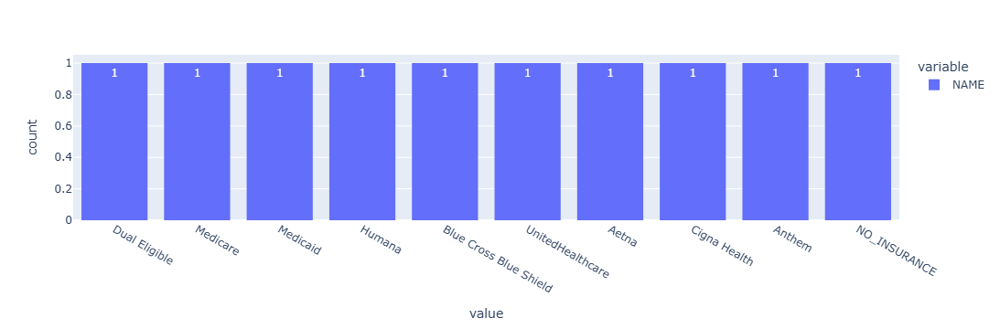

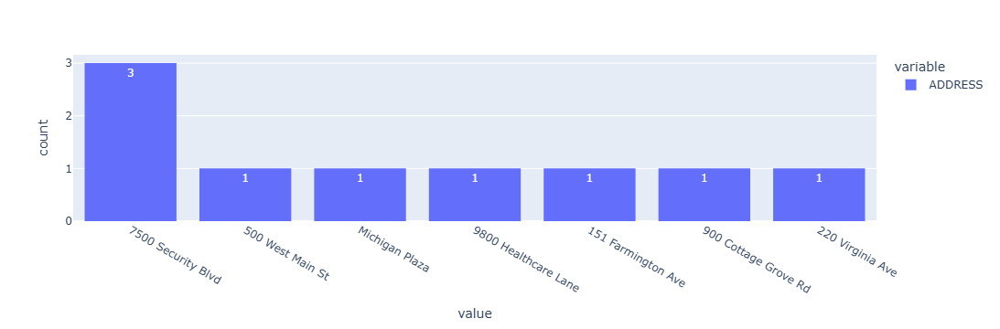

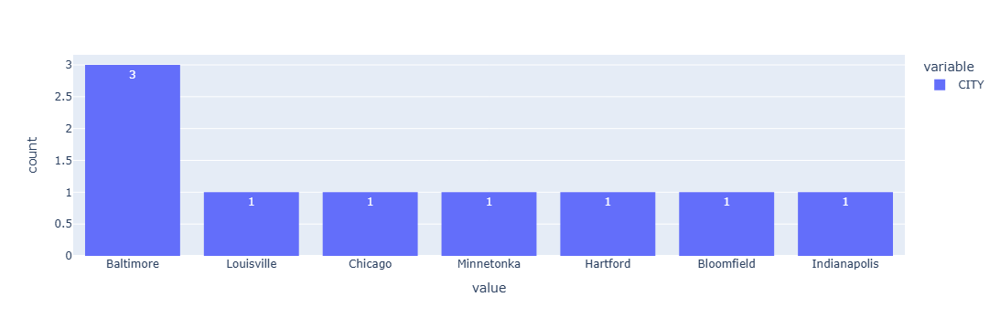

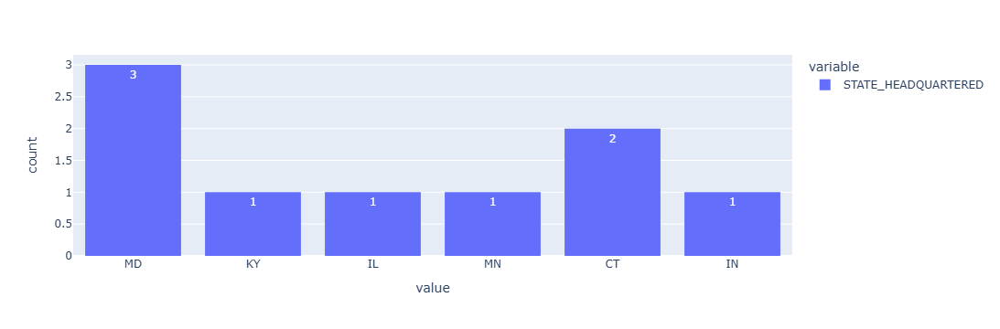

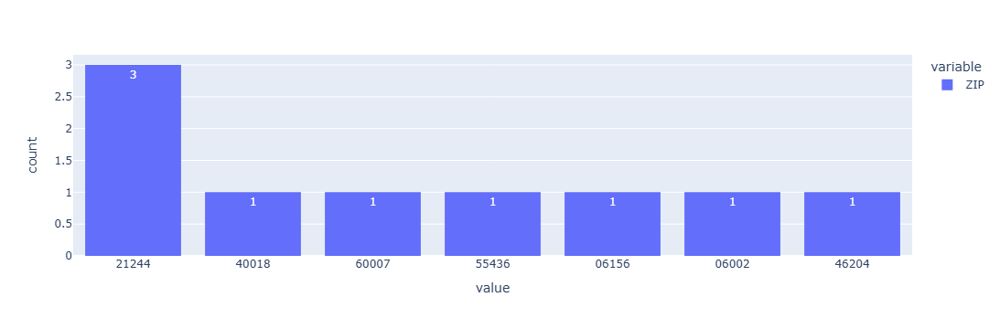

...

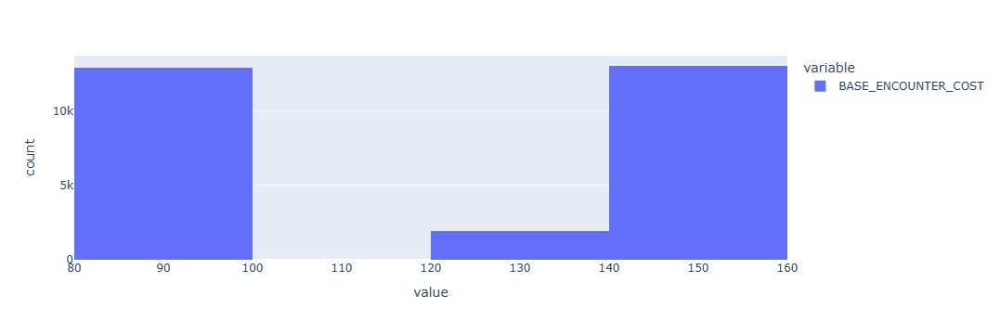

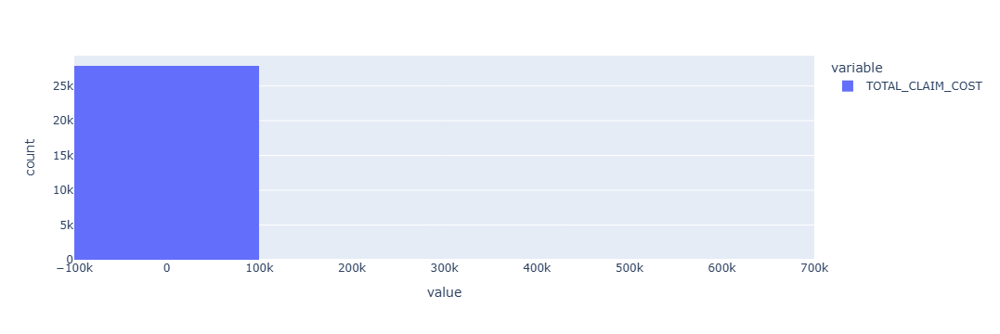

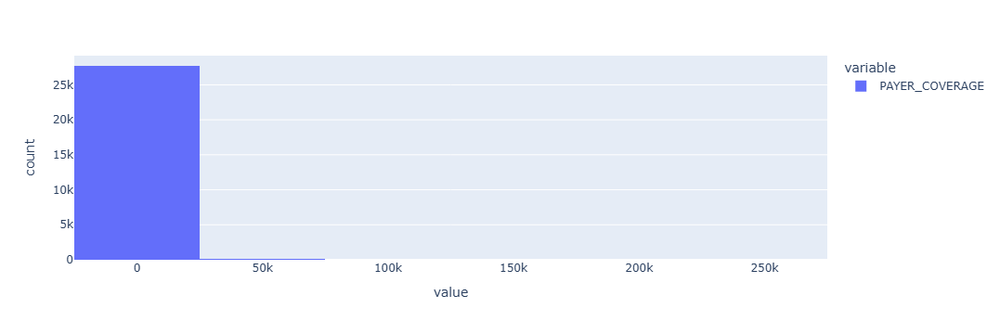

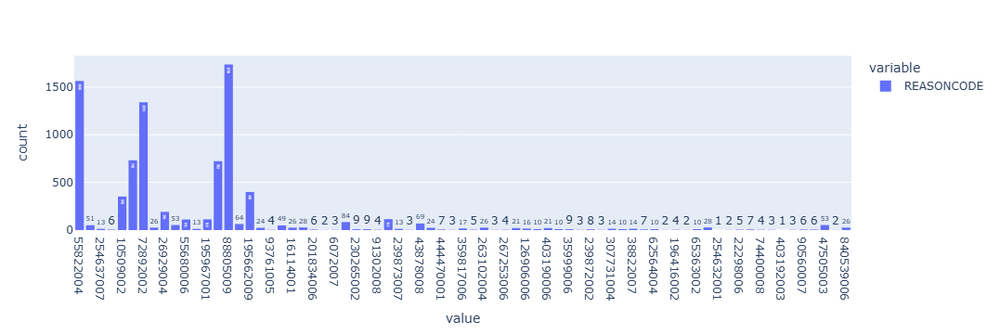

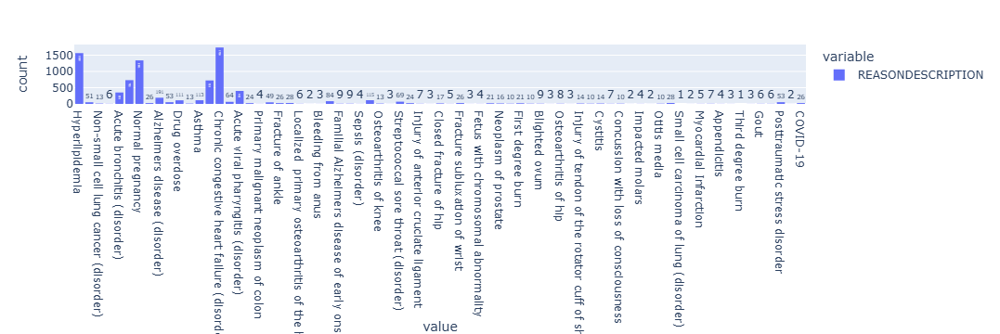

In [13]:
for N,df in dfs:
        for col in df.columns:
            if df[col].dtypes!='str' and 'id' not in col.lower():
                fig=px.histogram(df[col],nbins=5)
                fig.show()
            elif df[col].dtypes=='str' and 'id' not in col.lower():
                fig=px.histogram(df[col],text_auto=True)
                fig.show()

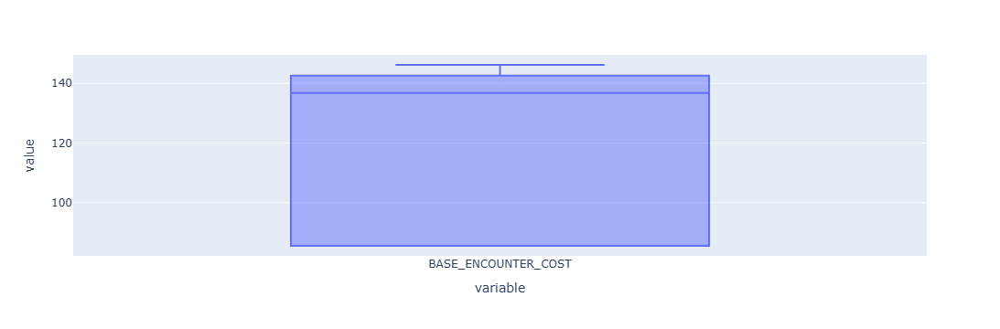

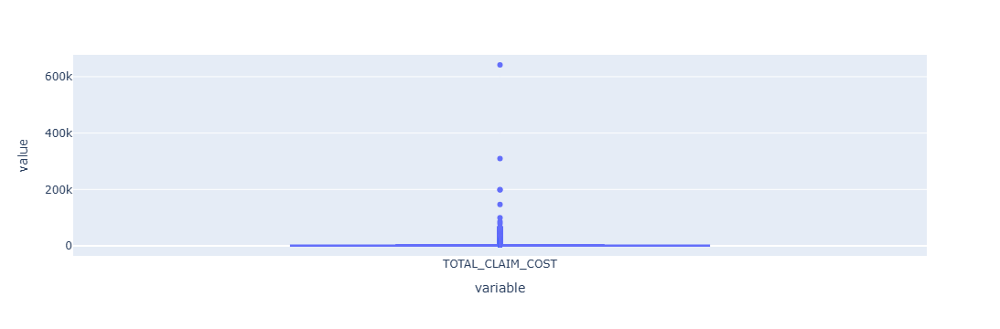

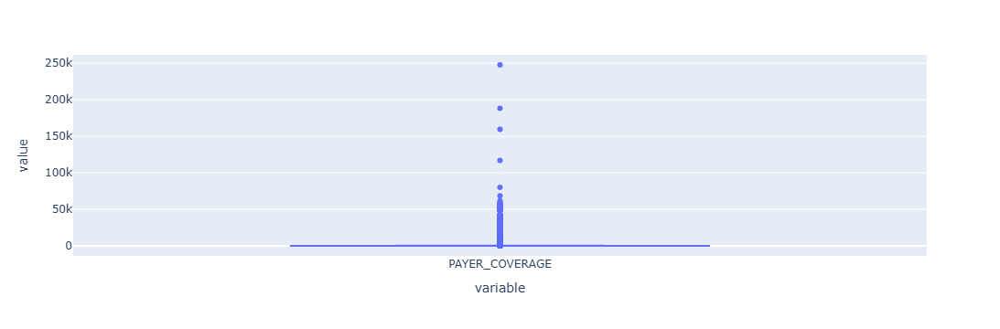

In [14]:
for i in dfs[2][1].columns:
    if dfs[2][1][i].dtypes!='str':
        fig=px.box(dfs[2][1][i])
        fig.show()

In [15]:
Paydf=dfs[2][1][['BASE_ENCOUNTER_COST','TOTAL_CLAIM_COST', 'PAYER_COVERAGE']]

In [16]:
Paydf=pd.melt(
    Paydf,
     value_vars=['BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE']
).rename(columns={'variable':'Cost_category','value':'cost'})

In [17]:
Paydf=Paydf.groupby('Cost_category').agg({'cost':'sum'}).reset_index().sort_values('cost',ascending=False)

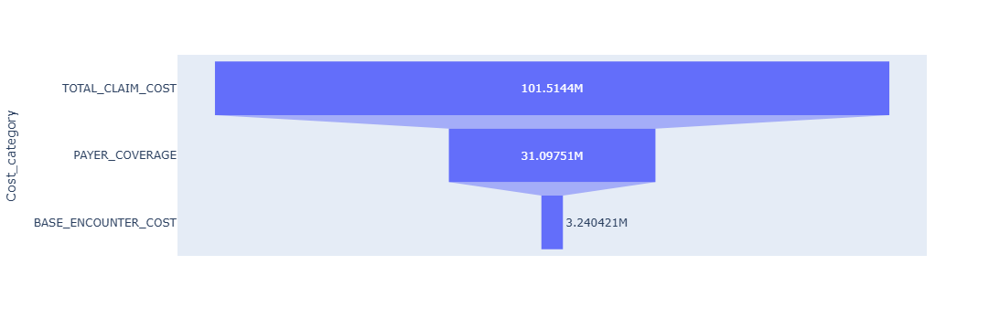

In [18]:
px.funnel(
    Paydf,
    x='cost',
    y='Cost_category'
)

In [19]:
dfs[2][1].describe().T

,count,mean,std,min,25%,50%,75%,max
BASE_ENCOUNTER_COST,27891.0,116.181614,28.410082,85.55,85.55,136.80,142.58,146.18
TOTAL_CLAIM_COST,27891.0,3639.682174,9205.595748,0.00,142.58,278.58,1412.53,641882.70
PAYER_COVERAGE,27891.0,1114.965652,4768.615576,0.00,0.00,28.44,155.77,247751.42


In [20]:
dfs[0][1].describe(include='object').T

C:\Users\bac\AppData\Local\Temp\ipykernel_27708\2173755130.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  dfs[0][1].describe(include='object').T


,count,unique,top,freq
Id,10,10,b3221cfc-24fb-339e-823d-bc4136cbc4ed,1
NAME,10,10,Dual Eligible,1
ADDRESS,9,7,7500 Security Blvd,3
CITY,9,7,Baltimore,3
STATE_HEADQUARTERED,9,6,MD,3
ZIP,9,7,21244,3
PHONE,9,8,1-877-267-2323,2


In [21]:
dfs[1][1].describe(include='object').T

C:\Users\bac\AppData\Local\Temp\ipykernel_27708\3861122336.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  dfs[1][1].describe(include='object').T


,count,unique,top,freq
Id,973,973,5605b66b-e92d-c16c-1b83-b8bf7040d51f,1
BIRTHDATE,973,879,1929-01-28,4
DEATHDATE,0,0,NaN,NaN
PREFIX,973,3,Mr.,494
FIRST,973,841,Armando772,3
LAST,973,498,Heaney114,6
SUFFIX,0,0,NaN,NaN
MAIDEN,973,280,,588
MARITAL,973,3,M,783
RACE,973,6,white,679


In [22]:
dfs[2][1].describe(include='object').T

C:\Users\bac\AppData\Local\Temp\ipykernel_27708\2992531475.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  dfs[2][1].describe(include='object').T


,count,unique,top,freq
Id,27891,27891,32c84703-2481-49cd-d571-3899d5820253,1
START,27891,27541,2016-12-08 10:00:40,3
STOP,27891,27765,2016-12-08 10:15:40,3
PATIENT,27891,974,1712d26d-822d-1e3a-2267-0a9dba31d7c8,1381
ORGANIZATION,27891,1,d78e84ec-30aa-3bba-a33a-f29a3a454662,27891
PAYER,27891,10,7caa7254-5050-3b5e-9eae-bd5ea30e809c,11371
ENCOUNTERCLASS,27891,6,ambulatory,12537
CODE,27891,45,185347001,5261
DESCRIPTION,27891,53,Encounter for problem (procedure),4308
REASONCODE,8350,73,88805009,1738


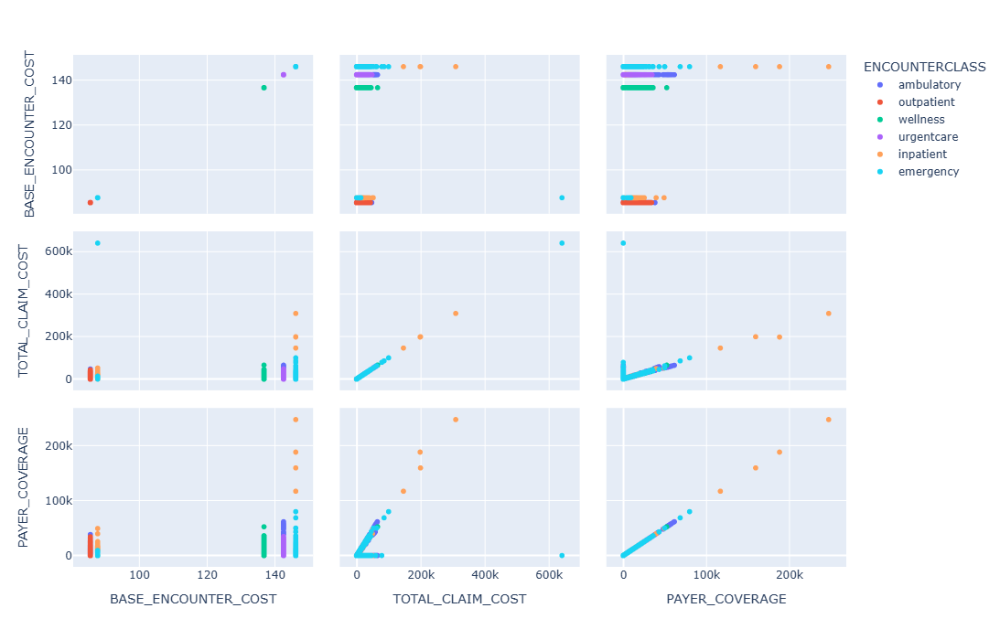

In [23]:
fig=px.scatter_matrix(dfs[2][1],
                      dimensions=['BASE_ENCOUNTER_COST','TOTAL_CLAIM_COST', 'PAYER_COVERAGE'],
                      color='ENCOUNTERCLASS')
fig.update_layout(
    width=800,
    height=700
)

In [24]:
# Total Insurance Companies
print('Total Insurance Companies :',len(dfs[0][1]['NAME'].unique())-1)

Total Insurance Companies : 9


In [25]:
dfs[1][1].head(1)

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON
0,5605b66b-e92d-c16c-1b83-b8bf7040d51f,1977-03-19,None,Mrs.,Nikita578,Erdman779,None,Leannon79,M,white,nonhispanic,F,Wakefield Massachusetts US,510 Little Station Unit 69,Quincy,Massachusetts,Norfolk County,02186,42.290937,-70.975503


In [26]:
BD=pd.to_datetime(dfs[1][1]['BIRTHDATE'])

In [27]:
import datetime as dt

In [28]:
AGE=(dt.datetime.now().year - BD.dt.year).astype('int8')

In [29]:
dt.datetime.now().year

2026

In [30]:
print('Average Age of a Patient :',round(AGE.mean(),0))

Average Age of a Patient : 74.0


In [31]:
round((dfs[1][1]['GENDER'].value_counts()/(494+479))*100,0).astype(str).str[:-2]+'%'

GENDER
M    51%
F    49%
Name: count, dtype: str

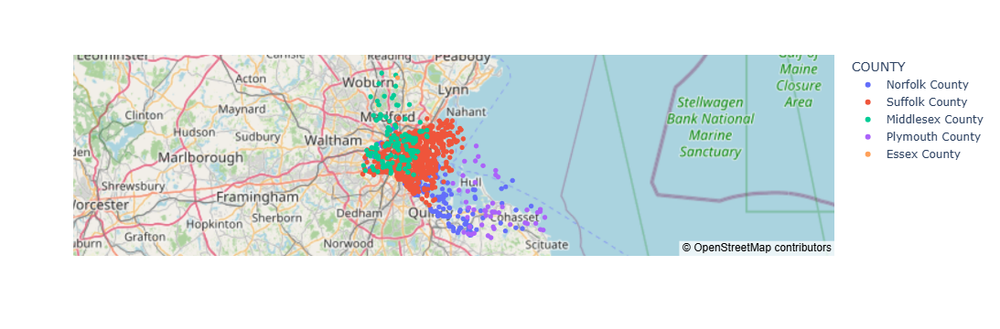

In [32]:
px.scatter_map(
    dfs[1][1],
    lat='LAT',
    lon='LON',
    hover_name='STATE',
    color='COUNTY',
    map_style='open-street-map')

# Dashboard Building

In [33]:
# Total Patients
dfs[1][1]['Id'].nunique()

973

In [34]:
dfs[2][1]['START']=pd.to_datetime(dfs[2][1]['START'])
dfs[2][1]['STOP']=pd.to_datetime(dfs[2][1]['STOP'])

In [35]:
Time_wise_patients=dfs[2][1].groupby(
    [dfs[2][1]['START'].dt.year,dfs[2][1]['START'].dt.month]).agg(
    {'PATIENT':'nunique'}
    )

In [36]:
This_month=Time_wise_patients.iloc[-2,-1]
Last_month=Time_wise_patients.iloc[-3,-1]
Growth=((This_month/Last_month)-1)*100
print(str(round(Growth))+'%')

-6%


In [37]:
Time_wise_Encounters=dfs[2][1].groupby(
    [dfs[2][1]['START'].dt.year,dfs[2][1]['START'].dt.month]).agg(
    {'Id':'nunique'})

In [38]:
This_month=Time_wise_Encounters.iloc[-2,-1]
Last_month=Time_wise_Encounters.iloc[-3,-1]
Growth=((This_month/Last_month)-1)*100
print(str(round(Growth))+'%')

-5%


In [39]:
years=[i[0] for i in Time_wise_Encounters.index] # Extraction of years from index
month=[i[1] for i in Time_wise_Encounters.index] # Extraction of months from index

In [40]:
Time_wise_Encounters['years']=years
Time_wise_Encounters['month']=month

In [41]:
Time_wise_Encounters=Time_wise_Encounters.reset_index(drop=True)

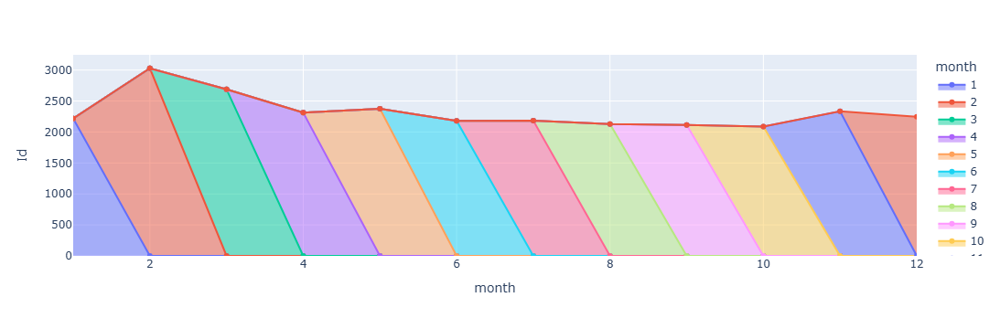

In [42]:
ME=Time_wise_Encounters.groupby('month').agg({'Id':'sum'}).reset_index()
px.area(ME,x='month',y='Id',markers='o',color='month')

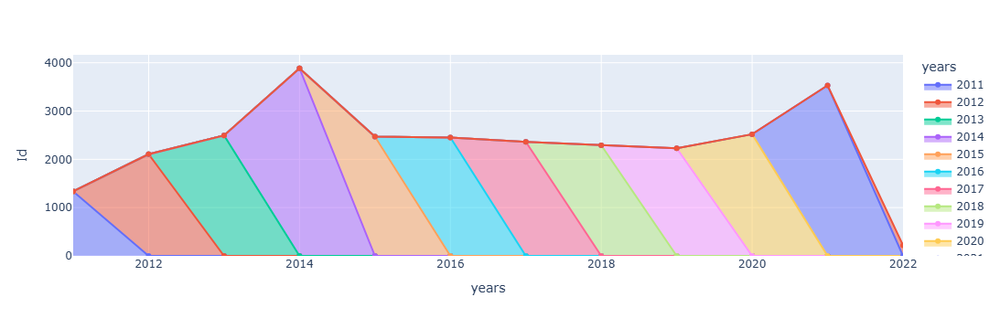

In [43]:
YE=Time_wise_Encounters.groupby('years').agg({'Id':'sum'}).reset_index()
px.area(YE,x='years',y='Id',markers='o',color='years')

In [44]:
from datetime import datetime as dt

In [45]:
dfs[1][1]['Age']=dt.now().year-pd.to_datetime(
    dfs[1][1]['BIRTHDATE']).dt.year

In [46]:
dfs[1][1]['Age_bin']=pd.cut(
    dfs[1][1]['Age'],
    bins=5,
    labels=['35 to 49','49 to 63','63 to 76','76 to 90','90 to 104']
)

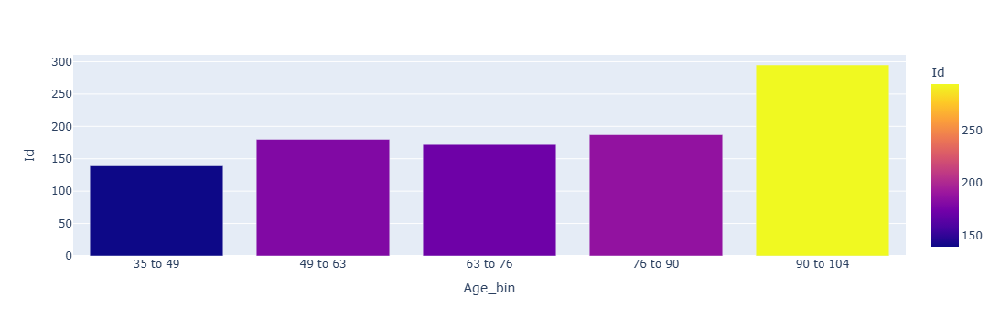

In [47]:
Age_wise_patients=dfs[1][1].groupby('Age_bin',observed=True).agg({'Id':'nunique'}).reset_index()
px.bar(Age_wise_patients,x='Age_bin',y='Id',color='Id')

In [48]:
GD=dfs[1][1]['GENDER'].value_counts().reset_index()

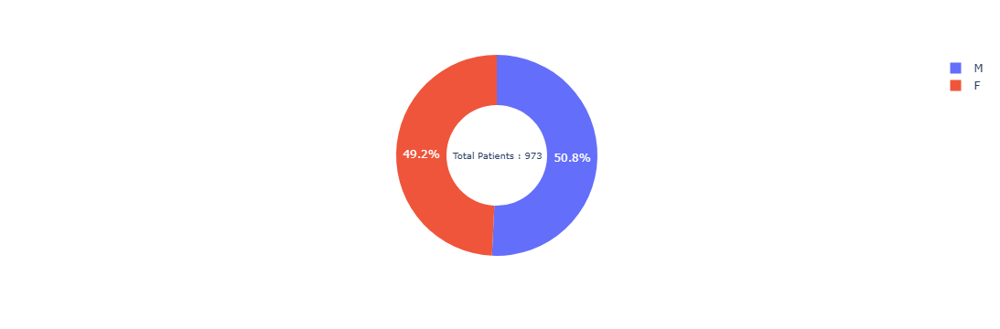

In [49]:
fig=px.pie(GD,
          names=GD['GENDER'],
          values=GD['count'],
          hole=0.5)
fig.add_annotation(
    text=f'Total Patients : {dfs[1][1]['Id'].nunique()}',
    x=0.5,
    y=0.5,
    font_size=10,
    showarrow=False)
fig.show()

In [50]:
dfs[2][1].head(1)['PAYER']

0    b1c428d6-4f07-31e0-90f0-68ffa6ff8c76
Name: PAYER, dtype: str

In [51]:
Payers=pd.read_csv('payers.csv')

In [52]:
Payers.head(1)

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,21244.0,1-877-267-2323


In [53]:
payer=pd.merge(dfs[2][1],Payers,left_on='PAYER',right_on='Id',how='inner')

In [54]:
Top_Payers=payer.groupby('NAME').agg({'PAYER_COVERAGE':'sum'}).sort_values('PAYER_COVERAGE').iloc[::,:].reset_index()

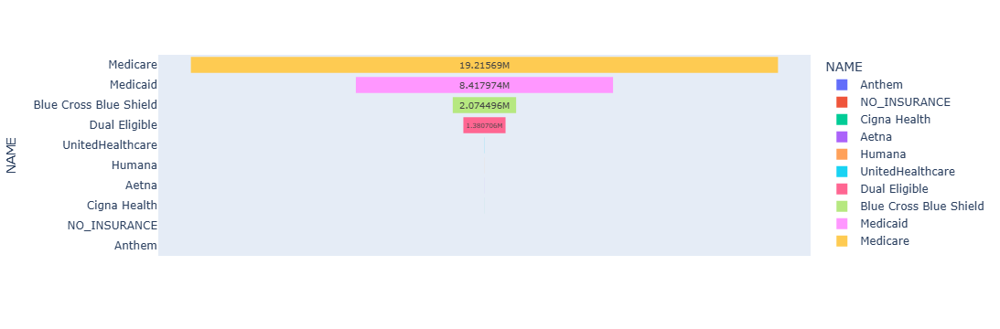

In [55]:
fig=px.funnel(Top_Payers,x='PAYER_COVERAGE',y='NAME',color='NAME')
fig.update_traces(
    textposition='inside',
    textfont_size=14
)

In [56]:
# Top Encounter Class
dfs[2][1]['DESCRIPTION']=dfs[2][1]['DESCRIPTION'].str.replace('(procedure)','')
Top_Encounters=dfs[2][1].groupby('DESCRIPTION').agg(
    {'Id':'count'}).sort_values('Id').iloc[::,:].reset_index().tail(5)

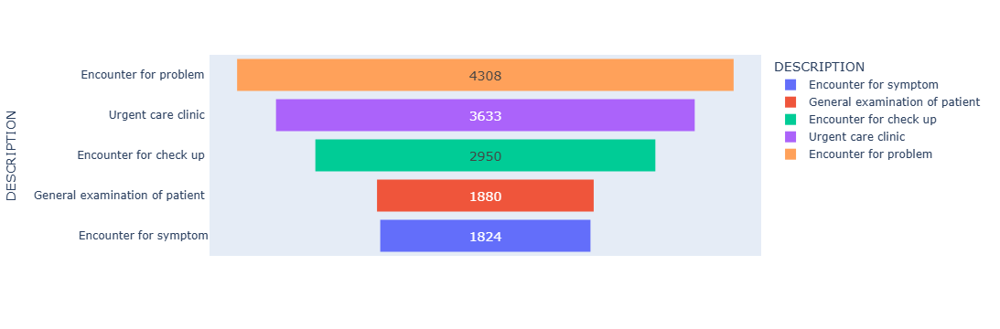

In [57]:
fig=px.funnel(Top_Encounters,x='Id',y='DESCRIPTION',color='DESCRIPTION')
fig.update_traces(
    textposition='inside',
    textfont_size=14)

In [58]:
Desc=dfs[2][1].groupby('ENCOUNTERCLASS').agg({'Id':'count'}).reset_index().sort_values('Id').tail(5)

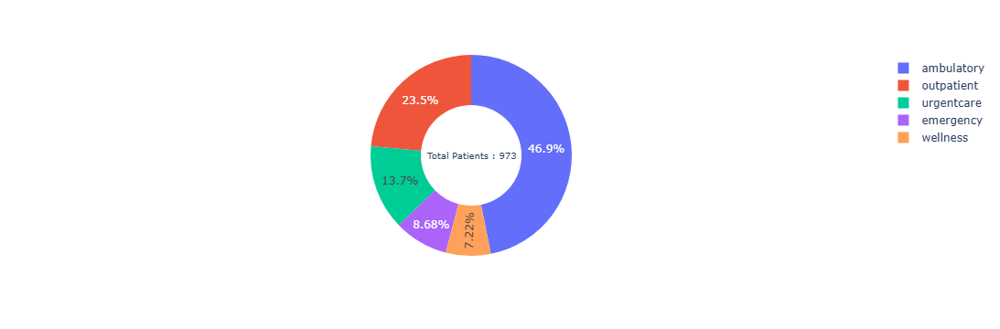

In [59]:
fig=px.pie(Desc,
          names='ENCOUNTERCLASS',
          values='Id',
          hole=0.5)
fig.add_annotation(
    text=f'Total Patients : {dfs[1][1]['Id'].nunique()}',
    x=0.5,
    y=0.5,
    font_size=10,
    showarrow=False)
fig.show()

In [60]:
# Total Patients
dfs[1][1]['Id'].nunique()

973

In [61]:
# Total Encounters
dfs[2][1]['Id'].nunique()

27891

In [62]:
# Total Insurance Payers
dfs[0][1]['Id'].nunique()

10

In [63]:
# Total Medical Procedures
dfs[2][1]['DESCRIPTION'].nunique()

53

In [64]:
# Total Claim Cost
'$' + str(round(dfs[2][1]['TOTAL_CLAIM_COST'].sum()/1000000)) + 'M'

'$102M'

In [65]:
# Payer Coverage 
'$' + str(round(dfs[2][1]['PAYER_COVERAGE'].sum()/1000000)) + 'M'

'$31M'

In [66]:
# Patient Responsibility
'$' + str(round(dfs[2][1]['BASE_ENCOUNTER_COST'].sum()/1000000)) + 'M'

'$3M'